# The blob projection method of Cortez & Minion 2000

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fairyflies9/pyIBM/blob/main/tutorials/03_blob_projection_method.ipynb)

This notebook walks through the second coupling method in pyibm, the blob projection method of
R. Cortez and M. L. Minion, *The blob projection method for immersed boundary problems*,
J. Comput. Phys. 161 (2000) 428-453, and its implementation in `pyibm.coupling.blob`. Equation
numbers are the paper's unless we say otherwise; "Fovargue" is L. E. Fovargue's 2012 PhD thesis
(University of North Carolina at Chapel Hill), whose compact blob and $p_1, p_2$ kernel form we
also use. The full references are at the end. We paraphrase; the papers are not redistributed.

The plan: why the singular force is projected (section 1), the blob functions and their moments
(2), the closed-form projected force of one point force (3), the curl-on-patches route that puts it
on the grid and the stream-function solve (4), moving the points: the bicubic stencil and the
divergence-free stream-function interpolation that pyibm uses by default (5), a side-by-side comparison with delta-function
spreading on one elastic ring (6), and the resolution guidance and open items (7;
`docs/numerics.md` keeps the same guidance for reference).

Every number quoted in the text is printed by a cell here, cited to the paper by equation, figure
or section, or measured with this code and labelled as such, with its source named: the runs at
the paper's resolution in section 6, which are too long for a notebook, and the `pyibm` module
docstrings and tests that sections 4 and 7 point to. The notebook uses coarse grids and
short runs (the last cell prints the total time, well under a minute on a laptop), and each section says
what a converged run would use.

In [1]:
# On Google Colab, fetch the repository first: the notebook reads example inputs and test data from it.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isfile(os.path.join("..", "pyibm", "__init__.py")):
    if not os.path.isdir("pyIBM"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/fairyflies9/pyIBM.git"], check=True)
    os.chdir(os.path.join("pyIBM", "tutorials"))

import os, sys, time

# Make the repository importable from the tutorials/ directory (or any directory inside it).
root = os.path.abspath(os.getcwd())
while not os.path.isfile(os.path.join(root, "pyibm", "__init__.py")):
    parent = os.path.dirname(root)
    if parent == root:
        raise RuntimeError("cannot find the pyIBM repository above " + os.getcwd())
    root = parent
if root not in sys.path:
    sys.path.insert(0, root)

%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import integrate

import pyibm
from pyibm.grid import Grid, layout_collocated
from pyibm.coupling.blob import BlobProjection, get_blob
from pyibm.coupling.delta import DeltaCoupling
from pyibm.kernels import get_kernel
from pyibm.fluid.periodic_fft import PeriodicFFTSolver, periodic_symbols, d0x, d0y, divergence
from pyibm.structures import Structure, Springs, Beams, Hooks, compute_forces, spring_forces, beam_forces
from pyibm.inputfile import (Parameters, FluidParams, TimeParams, GridParams, SolverParams,
                             BCParams, StructureParams, OutputParams)
from pyibm.driver import Simulation

plt.rcParams["figure.dpi"] = 100
T_START = time.perf_counter()
print("pyibm", pyibm.__version__)

pyibm 0.1.0.dev0


## 1. Why project the singular force (eqs. 1-6, 11-12)

The paper starts from the incompressible Navier-Stokes equations (eq. 1),
$u_t = -(u\cdot\nabla)u - \nabla p + \nu\Delta u + F$, $\nabla\cdot u = 0$, with the force
concentrated on the immersed curve $z(\alpha, t)$ (eq. 2):

$$F(x, t) = \int_0^L f(\alpha, t)\,\delta\big(x - z(\alpha, t)\big)\,d\alpha .$$

This is a line integral of a two-dimensional delta function, so $F$ is singular. The curve moves
with the fluid (eq. 3): $dz/dt = u(z(\alpha,t), t)$.

**Hodge decomposition** (Theorem 2.1 and eq. 4). Any vector field $w$ on the domain splits uniquely
as $w = u + \nabla\xi$ with $\nabla\cdot u = 0$; $\xi$ solves $\Delta\xi = \nabla\cdot w$ with the
boundary condition that goes with the decomposition, and $u = w - \nabla\xi =: Pw$ is the
projection of $w$ onto divergence-free fields. In two dimensions the same projection can be written
with a stream function (eq. 5): $Pw = (\psi_y, -\psi_x)$ where $-\Delta\psi = \nabla\times w$.
With $P$ the momentum equation reads (eq. 6)
$u_t = P[-(u\cdot\nabla)u - \nabla p + \nu\Delta u + F]$, and on a periodic box the pressure
gradient is a gradient, so $P$ removes it and it drops out altogether.

**The point of the method** (eq. 11). On the periodic box $P$ is linear, so

$$u_t = P\big[-(u\cdot\nabla)u + \nu\Delta u\big] + PF .$$

The terms evaluated on the grid and the term that lives on the immersed boundary are projected
separately. Fully discrete, with forward Euler for the exposition (eq. 12),
$(u^{n+1}_{ij} - u^n_{ij})/\Delta t = P[-(u^n\cdot\nabla_h)u^n + \nu\Delta_h u^n]_{ij} + (PF^n)_{ij}$.
So we are free to replace the singular $F$ by a regularised $\tilde F$ whose projection
$P\tilde F$ is known in closed form, and to put $P\tilde F$ on the grid directly, instead of
spreading the force with a discrete delta function (the paper's eq. 7) and then projecting it
numerically with the rest of the right-hand side.

In pyibm the discrete $P$ of the periodic FFT back end is `PeriodicFFTSolver.project`
(Peskin & McQueen 1996 eqs. 14.48-14.53): in Fourier space $\hat u = \hat w - s\,q$ with
$q = (s\cdot\hat w)/|s|^2$, $s = (\sin(2\pi k_1/N_x), \sin(2\pi k_2/N_y))$ the symbol of the
centred difference $D_0$ (up to $i/h$), and $q = 0$ on the four modes where $s = 0$. The cell
below checks the properties the blob method relies on: $D_0\cdot Pw = 0$, $P$ is linear and
idempotent, it removes every discrete gradient, it leaves the discrete curl untouched (this is
what section 4 exploits), and it leaves the box mean alone (which is why section 4 has to add
the mean separately).

In [2]:
N = 64
grid = Grid.periodic_box(1.0, 1.0, N, N)
h = grid.dx
XX, YY = grid.meshgrid("nodes")
sym = periodic_symbols(N, N, h)

def project(w1, w2):
    '''The discrete Hodge projection P of the periodic back end applied to a node field (w1, w2).'''
    p1, p2 = PeriodicFFTSolver.project(np.fft.fft2(w1), np.fft.fft2(w2), sym)
    return np.real(np.fft.ifft2(p1)), np.real(np.fft.ifft2(p2))

def smooth_field(rng, modes=6):
    '''A few random Fourier modes plus a constant: smooth, periodic, neither solenoidal nor a gradient.'''
    w = np.full((N, N), rng.normal())
    for _ in range(modes):
        kx, ky = rng.integers(-6, 7, size=2)
        w += rng.normal() * np.cos(2 * np.pi * (kx * XX + ky * YY) + rng.uniform(0, 2 * np.pi))
    return w

rng = np.random.default_rng(1)
w1, w2 = smooth_field(rng), smooth_field(rng)
u1, u2 = project(w1, w2)
scale = max(np.abs(d0x(w1, h)).max(), np.abs(d0y(w2, h)).max())
print("max |D0 . w|  / max|D0 w| = %.3e   (the test field is not divergence-free)"
      % (np.abs(divergence(w1, w2, h)).max() / scale))
print("max |D0 . Pw| / max|D0 w| = %.3e   (eq. 4: Pw is, to round-off)"
      % (np.abs(divergence(u1, u2, h)).max() / scale))

v1, v2 = smooth_field(rng), smooth_field(rng)
pv1, pv2 = project(v1, v2)
a, b = 0.7, -1.3
L1, L2 = project(a * w1 + b * v1, a * w2 + b * v2)
print("linearity    max |P(a w + b v) - a Pw - b Pv| = %.3e"
      % max(np.abs(L1 - a * u1 - b * pv1).max(), np.abs(L2 - a * u2 - b * pv2).max()))
pp1, pp2 = project(u1, u2)
print("idempotent   max |P(Pw) - Pw|               = %.3e" % max(np.abs(pp1 - u1).max(), np.abs(pp2 - u2).max()))

phi = smooth_field(rng)
gx, gy = d0x(phi, h), d0y(phi, h)
g1, g2 = project(gx, gy)
print("gradient     max |P(D0 phi)| = %.3e  for max |D0 phi| = %.3e: a discrete gradient is removed entirely"
      % (max(np.abs(g1).max(), np.abs(g2).max()), max(np.abs(gx).max(), np.abs(gy).max())))
curl_w = d0x(w2, h) - d0y(w1, h)
curl_u = d0x(u2, h) - d0y(u1, h)
print("curl         max |curl Pw - curl w| = %.3e  for max |curl w| = %.3e: the curl passes through"
      % (np.abs(curl_u - curl_w).max(), np.abs(curl_w).max()))
print("box mean     mean(w) = (%+.6f, %+.6f),  mean(Pw) = (%+.6f, %+.6f): the k = 0 mode passes through"
      % (w1.mean(), w2.mean(), u1.mean(), u2.mean()))

max |D0 . w|  / max|D0 w| = 1.189e+00   (the test field is not divergence-free)
max |D0 . Pw| / max|D0 w| = 5.385e-16   (eq. 4: Pw is, to round-off)
linearity    max |P(a w + b v) - a Pw - b Pv| = 3.109e-15
idempotent   max |P(Pw) - Pw|               = 1.332e-15
gradient     max |P(D0 phi)| = 4.306e-14  for max |D0 phi| = 9.986e+01: a discrete gradient is removed entirely
curl         max |curl Pw - curl w| = 8.527e-14  for max |curl w| = 1.449e+02: the curl passes through
box mean     mean(w) = (+0.345584, -0.257192),  mean(Pw) = (+0.345584, -0.257192): the k = 0 mode passes through


## 2. Blob functions (eqs. 13, 15, 16) and Fovargue's compact blob

Eq. 13 replaces the delta function in eq. 2 by a radial cutoff, or blob, of scale $\delta$:

$$\tilde F(x) = \Delta\ell \sum_{k=1}^M f_k\,\phi_\delta(x - z_k), \qquad
\phi_\delta(x) = \delta^{-2}\,\phi(|x|/\delta).$$

In pyibm the weight $\Delta\ell$ is the per-point quadrature weight `ds` and $f_k$ the force
density per unit length, the same quantities delta-function spreading uses. $\phi$ has unit mass
in 2D, $2\pi\int_0^\infty s\,\phi(s)\,ds = 1$, and the order of a blob is the number of moment
conditions it satisfies (section 4.1.1). Unlike the delta-function support, $\delta$ is a
numerical parameter of its own, not locked to a multiple of $h$ (section 3.1).

Three blobs:

- eq. 15, fourth order: $\phi_4(r) = \frac{1}{\pi}(2 - r^2)\,e^{-r^2}$. pyibm `gaussian4`, the
  paper's workhorse, run with $\delta = 4h$ and $\delta = 2h$.
- eq. 16, eighth order: $\phi_8(r) = \frac{1}{6\pi}(24 - 36r^2 + 12r^4 - r^6)\,e^{-r^2}$. Not in
  pyibm: the paper finds nothing to gain from it for volume conservation (section 4.1.1). We type
  it below only to check its moments.
- Fovargue 2012 eq. 2.30, compact: $\phi_\delta(r) = \frac{6}{\pi\delta^2}(1 - r^2/\delta^2)^5$
  for $r \le \delta$, zero beyond. pyibm `compact`; she ran it with $\delta = 3h$. It has unit mass
  but a nonzero second moment ($\delta^2/7$), so it is formally second order.

The **shape factor** $F(r) = 2\pi\int_0^r s\,\phi_\delta(s)\,ds$, defined right after eq. 14, is
the fraction of the blob mass inside radius $r$; $F \to 1$ and $F' = 2\pi r\phi_\delta$. In closed
form, with $\rho = r/\delta$: gaussian4 $F = 1 - (1 - \rho^2)e^{-\rho^2}$, compact
$F = 1 - (1 - \rho^2)^6$.

`pyibm.coupling.blob.get_blob(name)` returns an object with `phi(r, delta)` ($\phi_\delta$),
`shape_factor(r, delta)` ($F$), `dphi_over_r(r, delta)` ($\phi_\delta'(r)/r$, needed for the curl
in section 4) and `kernels(r, delta)` ($p_1, p_2$ of section 3). We compute the radial moments
$m_p = 2\pi\int_0^\infty s^{p+1}\phi(s)\,ds$ by quadrature ($m_0$ is the mass) and check the shape
factors against the integral that defines them.

In [3]:
delta = 1.0
g4, cp = get_blob("gaussian4"), get_blob("compact")

def phi8(r, delta=1.0):
    '''Eq. 16, the eighth-order cutoff, scaled like the others: phi(r/delta)/delta^2.'''
    rho2 = (r / delta) ** 2
    return (24 - 36 * rho2 + 12 * rho2**2 - rho2**3) * np.exp(-rho2) / (6 * np.pi * delta**2)

far = 12.0 * delta                 # exp(-144) is far below double precision: a safe finite upper limit
cases = [("gaussian4 (eq. 15)", lambda r: g4.phi(r, delta), far),
         ("phi_8 (eq. 16)", phi8, far),
         ("compact (Fovargue 2.30)", lambda r: cp.phi(r, delta), delta)]
print("radial moments m_p = 2 pi int s^(p+1) phi(s) ds, delta = 1 (m_0 = mass; odd moments vanish by symmetry)")
print("%-26s %10s %10s %10s %10s" % ("blob", "m_0", "m_2", "m_4", "m_6"))
for name, fn, upper in cases:
    ms = [integrate.quad(lambda s, p=p: 2 * np.pi * s ** (p + 1) * fn(s), 0.0, upper,
                         epsabs=1e-12, epsrel=1e-12, limit=200)[0] for p in (0, 2, 4, 6)]
    print("%-26s %10.6f %10.6f %10.6f %10.6f" % (name, *ms))
print("compact: m_2 = delta^2/7 = %.6f, m_4 = delta^4/28 = %.6f" % (1 / 7, 1 / 28))
print("gaussian4: mass inside r = 2 delta is F(2 delta) = %.4f: a disc cut there keeps %.1f %% too much mass "
      "(the tail beyond sqrt(2) delta is negative)" % (g4.shape_factor(2.0 * delta, delta), 100 * (g4.shape_factor(2.0 * delta, delta) - 1)))
square = integrate.dblquad(lambda y, x: g4.phi(np.hypot(x, y), delta), -2 * delta, 2 * delta, -2 * delta, 2 * delta,
                           epsabs=1e-12, epsrel=1e-12)[0]
print("gaussian4: mass in the square |x|, |y| <= 2 delta = %.4f (%+.1f %%)" % (square, 100 * (square - 1)))

print()
print("shape factor F(r) = 2 pi int_0^r s phi(s) ds against the closed forms")
r = np.array([0.5, 1.0, 2.0]) * delta
rho2 = (r / delta) ** 2
closed = {"gaussian4": 1 - (1 - rho2) * np.exp(-rho2), "compact": 1 - np.clip(1 - rho2, 0, None) ** 6}
for name, blob in (("gaussian4", g4), ("compact", cp)):
    Fq = np.array([integrate.quad(lambda s: 2 * np.pi * s * blob.phi(s, delta), 0.0, ri,
                                  epsabs=1e-13, epsrel=1e-13)[0] for ri in r])
    print("%-10s r/delta = %s  quadrature %s  shape_factor %s  closed form %s"
          % (name, r / delta, np.round(Fq, 8), np.round(blob.shape_factor(r, delta), 8), np.round(closed[name], 8)))

radial moments m_p = 2 pi int s^(p+1) phi(s) ds, delta = 1 (m_0 = mass; odd moments vanish by symmetry)
blob                              m_0        m_2        m_4        m_6
gaussian4 (eq. 15)           1.000000  -0.000000  -2.000000 -12.000000
phi_8 (eq. 16)               1.000000  -0.000000  -0.000000   0.000000
compact (Fovargue 2.30)      1.000000   0.142857   0.035714   0.011905
compact: m_2 = delta^2/7 = 0.142857, m_4 = delta^4/28 = 0.035714
gaussian4: mass inside r = 2 delta is F(2 delta) = 1.0549: a disc cut there keeps 5.5 % too much mass (the tail beyond sqrt(2) delta is negative)
gaussian4: mass in the square |x|, |y| <= 2 delta = 1.0318 (+3.2 %)

shape factor F(r) = 2 pi int_0^r s phi(s) ds against the closed forms
gaussian4  r/delta = [0.5 1.  2. ]  quadrature [0.41589941 1.         1.05494692]  shape_factor [0.41589941 1.         1.05494692]  closed form [0.41589941 1.         1.05494692]
compact    r/delta = [0.5 1.  2. ]  quadrature [0.82202148 1.         1.        ]  

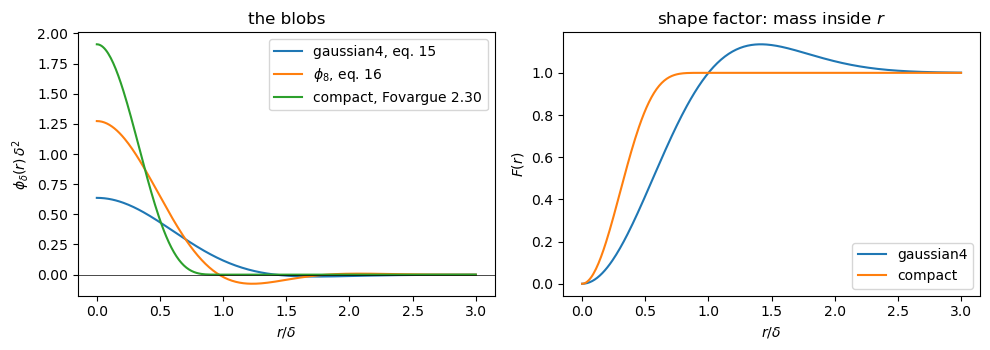

In [4]:
rr = np.linspace(0.0, 3.0, 301)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.plot(rr, g4.phi(rr, delta), label="gaussian4, eq. 15")
ax.plot(rr, phi8(rr, delta), label="$\\phi_8$, eq. 16")
ax.plot(rr, cp.phi(rr, delta), label="compact, Fovargue 2.30")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("$r/\\delta$"); ax.set_ylabel("$\\phi_\\delta(r)\\,\\delta^2$"); ax.set_title("the blobs")
ax.legend()
ax = axes[1]
ax.plot(rr, g4.shape_factor(rr, delta), label="gaussian4")
ax.plot(rr, cp.shape_factor(rr, delta), label="compact")
ax.set_xlabel("$r/\\delta$"); ax.set_ylabel("$F(r)$"); ax.set_title("shape factor: mass inside $r$")
ax.legend()
plt.tight_layout()
plt.show()

## 3. The projected force of one point force (eq. 14)

In free space the projection of the regularised force of eq. 13 is explicit (eq. 14, which the
paper takes from the vortex and impulse method literature):

$$P\tilde F(x) = \Delta\ell \sum_k \left[ \tfrac12 f_k\,\phi_\delta(r) +
\frac{1}{2\pi}\big(f_k - 2(f_k\cdot\hat x_k)\hat x_k\big)\,\frac{rF'(r) - 2F(r)}{2r^2} \right],
\qquad r = |x - z_k|,\ \hat x_k = \frac{x - z_k}{r}.$$

Each term is a regularised dipole oriented along $f_k$; the paper's Fig. 2 draws it for a unit
force $(0, 1)$ at the origin with $\delta = 1$. Using $F' = 2\pi r\phi_\delta$ the same sum reads
$\Delta\ell\sum_k [\,p_1(r)\,f_k - p_2(r)\,(f_k\cdot\hat x_k)\,\hat x_k\,]$ with the two radial
kernels

$$p_1 = \frac{rF' - F}{2\pi r^2} = \phi_\delta - \frac{F}{2\pi r^2}, \qquad
p_2 = \frac{rF' - 2F}{2\pi r^2} = \phi_\delta - \frac{F}{\pi r^2},$$

the form of Fovargue 2012 eq. 2.34. Two limits matter. At the point, $F \approx \pi\phi_\delta(0)r^2$,
so $p_1(0) = \phi_\delta(0)/2$ and $p_2(0) = 0$: half of the blob's peak survives the projection,
the other half was the gradient part. Far away, $F \to 1$ and $\phi_\delta \to 0$, so
$p_1 \to -1/(2\pi r^2)$ and $p_2 \to -1/(\pi r^2)$, the classical 2D potential dipole
$\Delta\ell\,[2(f\cdot\hat x)\hat x - f]/(2\pi r^2)$. The projected force therefore has no compact
support and decays like $1/r^2$ (section 3.2), which is why it is never evaluated on the whole grid.

pyibm: `BlobProjection.analytic_projected_force(f, X, ds, points)` evaluates this sum at any
points, in free space (no periodic images), at cost $O(MN)$; it is a reference for tests and
diagnostics, not the production route. `Blob.kernels(r, delta)` returns $p_1$ and $p_2$ with the
$r = 0$ limits set explicitly.

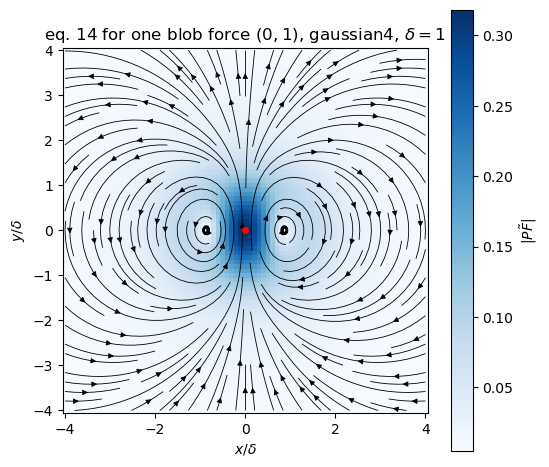

PF at the point itself: (0.000000, 0.318310);  ds f phi_delta(0)/2 = (0.000000, 0.318310) = ds f/(pi delta^2) for gaussian4
log-log slope of |PF| along the 45 degree ray, r = 4..64 delta: -2.0000  (a dipole decays like r^-2)
2 pi r^2 |PF| / ds at r = 64 delta: 1.000000  (the dipole limit is 1 on this ray)


In [5]:
delta = 1.0
box = Grid.periodic_box(16.0, 16.0, 16, 16)      # the analytic formula uses only the blob and delta
bp_g = BlobProjection(box, g4, delta)
f = np.array([[0.0, 1.0]]); Z = np.array([[0.0, 0.0]]); dl = np.array([1.0])

xs = np.linspace(-4.0, 4.0, 81)
PX, PY = np.meshgrid(xs, xs, indexing="ij")
PF = bp_g.analytic_projected_force(f, Z, dl, np.column_stack([PX.ravel(), PY.ravel()]))
U, V = PF[:, 0].reshape(PX.shape), PF[:, 1].reshape(PX.shape)

fig, ax = plt.subplots(figsize=(5.6, 5))
im = ax.pcolormesh(PX, PY, np.hypot(U, V), shading="auto", cmap="Blues")
ax.streamplot(xs, xs, U.T, V.T, color="k", density=1.3, linewidth=0.6, arrowsize=0.8)
ax.plot(0, 0, "ro", ms=4)
ax.set_aspect("equal"); ax.set_xlabel("$x/\\delta$"); ax.set_ylabel("$y/\\delta$")
ax.set_title("eq. 14 for one blob force $(0, 1)$, gaussian4, $\\delta = 1$")
fig.colorbar(im, ax=ax, label="$|P\\tilde F|$")
plt.tight_layout()
plt.show()

at0 = bp_g.analytic_projected_force(f, Z, dl, np.zeros((1, 2)))[0]
print("PF at the point itself: (%.6f, %.6f);  ds f phi_delta(0)/2 = (%.6f, %.6f) = ds f/(pi delta^2) for gaussian4"
      % (*at0, *(dl[0] * f[0] * g4.phi(0.0, delta) / 2)))
rr = delta * np.geomspace(4.0, 64.0, 16)
ray = np.column_stack([rr, rr]) / np.sqrt(2.0)           # the 45 degree ray, where |2 (f.x^) x^ - f| = 1
mag = np.hypot(*bp_g.analytic_projected_force(f, Z, dl, ray).T)
slope = np.polyfit(np.log(rr), np.log(mag), 1)[0]
print("log-log slope of |PF| along the 45 degree ray, r = 4..64 delta: %.4f  (a dipole decays like r^-2)" % slope)
print("2 pi r^2 |PF| / ds at r = 64 delta: %.6f  (the dipole limit is 1 on this ray)" % (2 * np.pi * rr[-1] ** 2 * mag[-1] / dl[0]))

gaussian4  p1(0) pi delta^2 = 1.0000 (= phi_delta(0) pi delta^2 / 2 = 1.0000),  p2(0) = 0.0
compact    p1(0) pi delta^2 = 3.0000 (= phi_delta(0) pi delta^2 / 2 = 3.0000),  p2(0) = 0.0


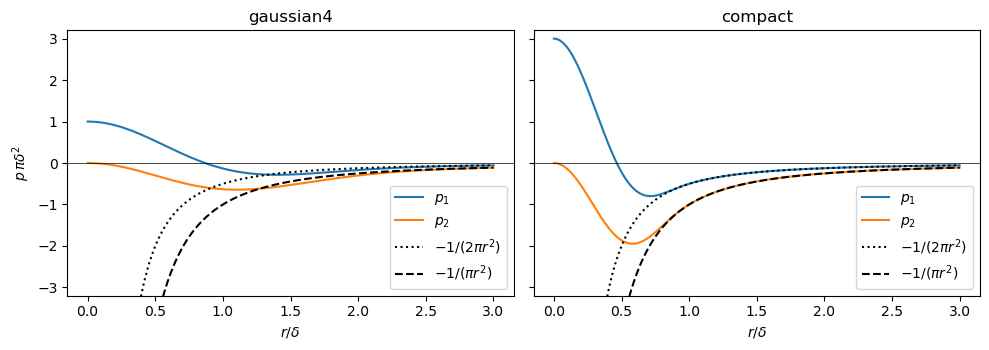

In [6]:
rho = np.linspace(0.0, 3.0, 601)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, blob) in zip(axes, (("gaussian4", g4), ("compact", cp))):
    p1, p2 = blob.kernels(rho * delta, delta)
    ax.plot(rho, p1 * np.pi * delta**2, label="$p_1$")
    ax.plot(rho, p2 * np.pi * delta**2, label="$p_2$")
    with np.errstate(divide="ignore"):
        ax.plot(rho[20:], -1 / (2 * rho[20:] ** 2), "k:", label="$-1/(2\\pi r^2)$")
        ax.plot(rho[20:], -1 / rho[20:] ** 2, "k--", label="$-1/(\\pi r^2)$")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylim(-3.2, 3.2); ax.set_xlabel("$r/\\delta$"); ax.set_title(name)
    ax.legend(loc="lower right")
    p10, p20 = blob.kernels(np.array([0.0]), delta)
    print("%-10s p1(0) pi delta^2 = %.4f (= phi_delta(0) pi delta^2 / 2 = %.4f),  p2(0) = %.1f"
          % (name, p10[0] * np.pi * delta**2, blob.phi(0.0, delta) * np.pi * delta**2 / 2, p20[0]))
axes[0].set_ylabel("$p\\,\\pi\\delta^2$")
plt.tight_layout()
plt.show()

## 4. Putting $P\tilde F$ on the grid: the curl-on-patches route (section 3.2)

Evaluating eq. 14 at all $N^2$ nodes costs $O(MN^2)$ and would still need the periodic images, so
the paper uses a fast route in the spirit of Anderson's method of local corrections. It rests on
two facts: the curl of $\tilde F$ equals the curl of $P\tilde F$ (the gradient part has none), and
that curl is concentrated near the points. So the curl of every blob force is evaluated
*analytically* on a small patch of nodes around its point, the patches are summed into one grid
field that is zero elsewhere, and one periodic Poisson solve of eq. 5,
$-\Delta_h\psi = \nabla\times\tilde F$, gives the stream function, from which
$P\tilde F = (D_y\psi, -D_x\psi)$ with centred differences. In the paper this Poisson solve is
shared with the projection of the advective and diffusive terms; in pyibm the fluid solver does
its own projection, and `projected_force` returns a force that passes through it unchanged
(section 1 showed why: $P$ is idempotent).

For one blob force the curl is, with the paper's sign $\nabla\times w = \partial_x w_2 - \partial_y w_1$,

$$\nabla\times\big[\Delta\ell\,f\,\phi_\delta(x - z)\big] = \Delta\ell\,\frac{\phi_\delta'(r)}{r}
\big[(x - z_x)\,f_y - (y - z_y)\,f_x\big],$$

so all a blob has to supply is $\phi_\delta'(r)/r$: `Blob.dphi_over_r`, which is
$-\frac{2}{\pi\delta^4}(3 - \rho^2)e^{-\rho^2}$ for gaussian4 and
$-\frac{60}{\pi\delta^4}(1 - \rho^2)^4$ inside the support of the compact blob. The patch must
contain the support, or, for a Gaussian blob, enough of the tail that the truncation at its edge
is no worse than the other errors. pyibm's default patch holds every node within $R = \delta$
(compact) or $R = 3\delta$ (gaussian4) of the point: a square of
$w = \lceil R/h + 1/2 \rceil$ nodes each side of the nearest node. We take gaussian4 out to $3\delta$ because a cut at $2\delta$ keeps too much of
its mass (the tail beyond $\sqrt2\,\delta$ is negative): 5.5 % too much inside a disc of radius
$2\delta$, 3.2 % inside a square of half-width $2\delta$ (both printed in section 2). The last column of the table below
shows what a square patch of that half-width does to the far field.

pyibm: `BlobProjection.curl_on_grid(f, X, ds)` evaluates the patches and accumulates them with
periodic index wrap; `BlobProjection.projected_force(f, X, ds)` solves $-L_h\psi = \text{curl}$
by FFT with the tight five-point Laplacian (why not the wide one: section 7), forms
$(D_{0y}\psi, -D_{0x}\psi)$ with the same symbols the fluid solver uses, and adds the box mean
$\sum_k ds_k f_k/(L_xL_y)$, which a stream function cannot carry and which $P$ preserves on a
periodic box. Two identities then hold to round-off whatever the blob or $\delta$:
$D_0\cdot P\tilde F = 0$ and $\sum_{ij} P\tilde F_{ij}\,h^2 = \sum_k f_k\,ds_k$.

gaussian4, delta = 4h: patch half-width 13 nodes (ceil(3 delta/h + 1/2)), 27 x 27 nodes per point


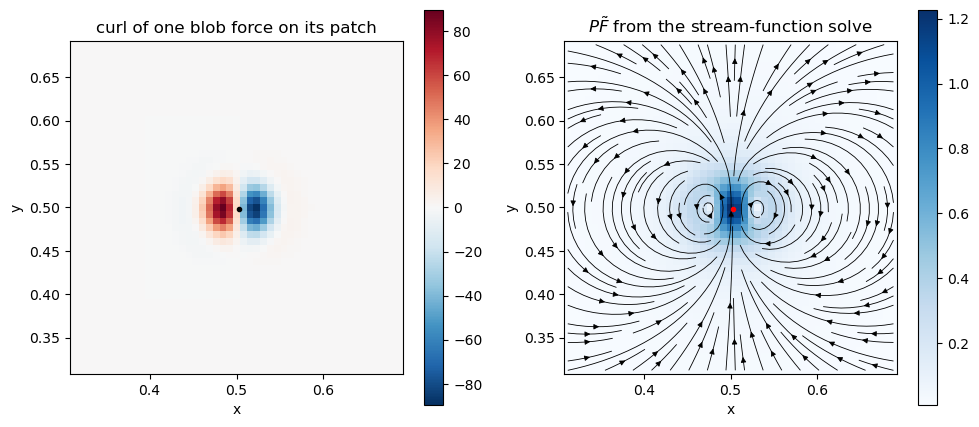

max |D0 . PF| / max |D0 PF| = 5.5e-16
sum PF h^2 = (-0.0000000000, 0.0039062500),  sum f ds = (0.0000000000, 0.0039062500)
box mean of the accumulated curl (dropped by the solve): -6.83e-06, max |curl| = 8.96e+01

gaussian4  200 random point forces, delta = 4h: max |D0 . PF| / max |D0 PF| = 6.9e-16, |sum PF h^2 - sum f ds| = 4.2e-17
compact    200 random point forces, delta = 4h: max |D0 . PF| / max |D0 PF| = 4.9e-16, |sum PF h^2 - sum f ds| = 4.2e-17


In [7]:
N = 128
grid = Grid.periodic_box(1.0, 1.0, N, N)
h = grid.dx
bp = BlobProjection(grid, get_blob("gaussian4"), 4.0 * h)       # the paper's main choice, delta = 4h
print("gaussian4, delta = 4h: patch half-width %d nodes (ceil(3 delta/h + 1/2)), %d x %d nodes per point"
      % ((bp.patch_half_width_cells,) + (2 * bp.patch_half_width_cells + 1,) * 2))

Z = np.array([[0.5 + 0.3 * h, 0.5 - 0.2 * h]]); f = np.array([[0.0, 1.0]]); dl = np.array([0.5 * h])
curl = bp.curl_on_grid(f, Z, dl)
Fx, Fy = bp.projected_force(f, Z, dl)
XX, YY = grid.meshgrid("nodes")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
win = slice(N // 2 - 24, N // 2 + 25)
vmax = np.abs(curl).max()
im = axes[0].pcolormesh(XX[win, win], YY[win, win], curl[win, win], shading="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].plot(*Z[0], "ko", ms=3); axes[0].set_aspect("equal"); axes[0].set_title("curl of one blob force on its patch")
fig.colorbar(im, ax=axes[0])
im = axes[1].pcolormesh(XX[win, win], YY[win, win], np.hypot(Fx, Fy)[win, win], shading="auto", cmap="Blues")
axes[1].streamplot(grid.x[win], grid.y[win], Fx[win, win].T, Fy[win, win].T, color="k", density=1.2, linewidth=0.6, arrowsize=0.8)
axes[1].plot(*Z[0], "ro", ms=3); axes[1].set_aspect("equal"); axes[1].set_title("$P\\tilde F$ from the stream-function solve")
fig.colorbar(im, ax=axes[1])
for ax in axes:
    ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout()
plt.show()

scale = max(np.abs(d0x(Fx, h)).max(), np.abs(d0y(Fy, h)).max())
print("max |D0 . PF| / max |D0 PF| = %.1e" % (np.abs(divergence(Fx, Fy, h)).max() / scale))
print("sum PF h^2 = (%.10f, %.10f),  sum f ds = (%.10f, %.10f)" % (Fx.sum() * h * h, Fy.sum() * h * h, *(f * dl[:, None]).sum(axis=0)))
print("box mean of the accumulated curl (dropped by the solve): %.2e, max |curl| = %.2e" % (curl.mean(), vmax))

print()
rng = np.random.default_rng(2)
M = 200
Zs = rng.uniform(0.2, 0.8, size=(M, 2)); fs = rng.normal(size=(M, 2)); dls = np.full(M, 0.5 * h)
for name in ("gaussian4", "compact"):
    bpn = BlobProjection(grid, get_blob(name), 4.0 * h)
    Gx, Gy = bpn.projected_force(fs, Zs, dls)
    scale = max(np.abs(d0x(Gx, h)).max(), np.abs(d0y(Gy, h)).max())
    total = np.array([Gx.sum(), Gy.sum()]) * h * h
    want = (fs * dls[:, None]).sum(axis=0)
    print("%-10s %d random point forces, delta = 4h: max |D0 . PF| / max |D0 PF| = %.1e, |sum PF h^2 - sum f ds| = %.1e"
          % (name, M, np.abs(divergence(Gx, Gy, h)).max() / scale, np.abs(total - want).max()))

### Near and far field error against $\delta/h$

How well does the grid field reproduce eq. 14? We put one point force on a $512^2$ grid, vary
$\delta/h$, and compare `projected_force` with `analytic_projected_force` in two places: on the
ring $r = 8\delta$ (far field, where only the dipole tail is left) and on the disc $r < 2\delta$
(near field), each relative to the largest value of the analytic field there. One subtlety: the
free-space dipole field integrates to only half the force over any disc around the point (the
other half sits in the conditionally convergent $1/r^2$ tail), while the periodic projection keeps
the full box mean, so half the mean $\sum_k ds_k f_k/(2L_xL_y)$ is added to the analytic field
before comparing; what is left is the image field of the periodic copies, $O((r/L)^4)$ here.

The last column repeats the far-field error with the wide Laplacian $D_{0x}^2 + D_{0y}^2$
(`laplacian="wide"`), the operator behind the fluid solver's own projection, whose symbol
decouples the grid into four sub-grids: a blob only a few cells wide then carries a checkerboard
of order one. This is why pyibm uses the tight five-point Laplacian by default. The last column
cuts the gaussian4 patch to $\lceil 2\delta/h + 1/2\rceil$ nodes each side instead of the default
$\lceil 3\delta/h + 1/2\rceil$.

In [8]:
N = 512
grid = Grid.periodic_box(1.0, 1.0, N, N)
h = grid.dx
XX, YY = grid.meshgrid("nodes")
Z = np.array([[0.5 + 0.37 * h, 0.5 - 0.21 * h]]); f = np.array([[0.6, 1.0]]); dl = np.array([0.01])
r = np.hypot(XX - Z[0, 0], YY - Z[0, 1])
half_mean = (dl[:, None] * f).sum(axis=0) / (2.0 * grid.Lx * grid.Ly)

def rel_error(bp, mask, Fx, Fy):
    pts = np.stack([XX[mask], YY[mask]], axis=1)
    want = bp.analytic_projected_force(f, Z, dl, pts) + half_mean
    got = np.stack([Fx[mask], Fy[mask]], axis=1)
    return np.abs(got - want).max() / np.abs(want).max()

t0 = time.perf_counter()
print("one point force, 512^2 grid; relative max error of the grid field against eq. 14")
print("%-10s %8s %6s %12s %12s %12s %14s" % ("blob", "delta/h", "patch", "far (tight)", "near (tight)", "far (wide)", "far (2 delta)"))
table = {}
for name in ("gaussian4", "compact"):
    for dfac in (2.0, 3.0, 4.0, 6.0, 8.0):
        delta = dfac * h
        bp = BlobProjection(grid, get_blob(name), delta)
        Fx, Fy = bp.projected_force(f, Z, dl)
        far_mask = np.abs(r - 8.0 * delta) < 0.5 * h
        near_mask = r < 2.0 * delta
        far, near = rel_error(bp, far_mask, Fx, Fy), rel_error(bp, near_mask, Fx, Fy)
        bw = BlobProjection(grid, get_blob(name), delta, laplacian="wide")
        Wx, Wy = bw.projected_force(f, Z, dl)
        far_wide = rel_error(bw, far_mask, Wx, Wy)
        table[(name, dfac)] = (far, near, far_wide)
        far_2d = "%14s" % "-"                         # the compact blob's support is delta: nothing to cut
        if name == "gaussian4":
            b2 = BlobProjection(grid, get_blob(name), delta, int(np.ceil(2.0 * dfac + 0.5)))   # patch cut at 2 delta
            Cx, Cy = b2.projected_force(f, Z, dl)
            far_2d = "%14.2e" % rel_error(b2, far_mask, Cx, Cy)
        print("%-10s %8.0f %6d %12.2e %12.2e %12.2e %s" % (name, dfac, bp.patch_half_width_cells, far, near, far_wide, far_2d))
print("(%.1f s)" % (time.perf_counter() - t0))
print()
print("near-field error ratio delta = 2h -> 8h: gaussian4 %.1f, compact %.1f  (second order in h/delta would give 16)"
      % (table[("gaussian4", 2.0)][1] / table[("gaussian4", 8.0)][1], table[("compact", 2.0)][1] / table[("compact", 8.0)][1]))

one point force, 512^2 grid; relative max error of the grid field against eq. 14
blob        delta/h  patch  far (tight) near (tight)   far (wide)  far (2 delta)
gaussian4         2      7     7.45e-03     8.83e-02     8.76e-02       4.50e-02


gaussian4         3     10     3.47e-03     4.06e-02     8.94e-03       7.88e-02
gaussian4         4     13     2.82e-03     2.31e-02     5.56e-03       9.84e-02


gaussian4         6     19     3.07e-03     1.03e-02     4.27e-03       1.16e-01
gaussian4         8     25     4.37e-03     5.78e-03     5.03e-03       1.23e-01


compact           2      3     5.05e-01     2.64e-01     2.51e+01              -
compact           3      4     6.34e-02     1.30e-01     1.55e+00              -
compact           4      5     1.44e-02     7.54e-02     5.55e-01              -


compact           6      7     2.52e-03     3.42e-02     6.39e-02              -
compact           8      9     2.46e-03     1.94e-02     1.53e-02              -
(1.3 s)

near-field error ratio delta = 2h -> 8h: gaussian4 15.3, compact 13.6  (second order in h/delta would give 16)


Reading the table: the near-field error is the $O((h/\delta)^2)$ discretisation error of forming
the curl on nodes and inverting a second-order Laplacian; it falls by close to the factor 16 that
second order predicts between $\delta = 2h$ and $8h$ (the ratios are printed under the table).
The far field of the compact blob follows the same trend, from half the field at $\delta = 2h$
to a few tenths of a percent at $6h$, while the far field of gaussian4 levels off at a few tenths
of a percent at every $\delta$: that floor is the patch truncation at $R = 3\delta$ (the tail beyond
it holds a tenth of a percent of the mass, with a negative sign: $F(3\delta) = 1 + 8e^{-9}$) plus the
periodic image field at $r = 8\delta$, not the Laplacian. Cutting the patch at $2\delta$ raises the
gaussian4 far-field error to several percent at every $\delta$ (last column), which is why the
default patch reaches $3\delta$. With the wide Laplacian the far-field error of the compact blob at
$\delta = 2$-$4h$ is of order one or more, which is that checkerboard, and gaussian4 at
$\delta = 2h$ is off by nearly ten percent. With the tight Laplacian the
compact blob reaches about a percent at $\delta = 4h$ and gaussian4 is below a percent
throughout; that is where the guidance of section 7 comes from. A converged study would also
take $N$ to 1024 and the gaussian4 patch out to $4\delta$, where `tests/test_blob.py` measures a
far-field error below $10^{-3}$ for both blobs at $\delta = 8h$.

## 5. Moving the points (section 3.1)

### 5.1 The bicubic stencil

The last step of the algorithm interpolates the new grid velocity to the points,
$\tilde u^{n+1}_k = I(u^{n+1}_{ij})$. In the blob projection method this operator does not have to
be tied to the spreading, unlike the immersed boundary method where eq. 9 uses the same $D_h$ as
eq. 7. Two of pyibm's three interpolations are built on a $4\times4$ patch of nodes around each
point and a bicubic polynomial interpolant, fourth-order accurate. Applied to $u$ and $v$ directly
it is `BlobProjection.interpolate_bicubic(u, v, X)` (or `interpolation="bicubic"` in the
constructor, `blob_interpolation = "bicubic"` in the input file): the tensor-product cubic Lagrange
form on the nodes $i_0 - 1, \ldots, i_0 + 2$ with $i_0 = \lfloor X/h \rfloor$ (and likewise in $y$),

$$U(X) = \sum_{i,j} u_{ij}\,L_i(X)\,L_j(Y), \qquad L_i(X) = \prod_{m \ne i}\frac{X - x_m}{x_i - x_m},$$

with periodic index wrap. It reproduces every cubic exactly, so the error is $O(h^4)$ for a smooth
field. For contrast we interpolate the same field with `DeltaCoupling.interpolate` and the peskin4
kernel (Peskin & McQueen 1996 eq. 14.61), which reproduces linear fields only and is second order.

In [9]:
def test_field(x, y):
    return np.sin(2 * np.pi * x) * np.cos(4 * np.pi * y) + 0.3 * np.cos(6 * np.pi * x + 2 * np.pi * y)

rng = np.random.default_rng(9)
P = rng.uniform(0.0, 1.0, size=(400, 2))          # random points, some with stencils that wrap around the box
exact = test_field(P[:, 0], P[:, 1])
delta_c = DeltaCoupling(get_kernel("peskin4"))
print("max interpolation error of a smooth periodic field at 400 random points")
print("%6s %14s %6s %14s %6s" % ("N", "bicubic", "rate", "peskin4", "rate"))
errs = []
for n in (16, 32, 64, 128, 256):
    g = Grid.periodic_box(1.0, 1.0, n, n)
    bpn = BlobProjection(g, get_blob("compact"), 3.0 * g.dx)
    GX, GY = g.meshgrid("nodes")
    U = bpn.interpolate_bicubic(test_field(GX, GY), test_field(GY, GX), P)
    V = delta_c.interpolate(test_field(GX, GY), P, layout_collocated(g))
    errs.append((np.abs(U[:, 0] - exact).max(), np.abs(V - exact).max()))
    if len(errs) == 1:
        print("%6d %14.3e %6s %14.3e %6s" % (n, errs[-1][0], "", errs[-1][1], ""))
    else:
        print("%6d %14.3e %6.2f %14.3e %6.2f" % (n, errs[-1][0], np.log2(errs[-2][0] / errs[-1][0]),
                                                   errs[-1][1], np.log2(errs[-2][1] / errs[-1][1])))

max interpolation error of a smooth periodic field at 400 random points
     N        bicubic   rate        peskin4   rate
    16      1.914e-02             2.829e-01       
    32      1.370e-03   3.80      7.949e-02   1.83
    64      8.292e-05   4.05      1.959e-02   2.02
   128      4.606e-06   4.17      4.953e-03   1.98
   256      3.465e-07   3.73      1.284e-03   1.95


### 5.2 Why pyibm interpolates the stream function

For a closed membrane, accuracy at the points is not the whole story. The markers enclose an area,
and that area changes at the rate of the flux of the interpolated velocity through the membrane,
which is the integral of its *continuous* divergence over the inside. So by default
(`interpolation="streamfunction"`, `blob_interpolation = "streamfunction"`) pyibm moves the points
with a velocity that is divergence-free in the continuous sense. From the grid velocity it forms the
discrete stream function, $-L_h\psi = D_{0x}v - D_{0y}u$ with the five-point Laplacian of section 4
(`BlobProjection.stream_function`), interpolates $\psi$ with the bicubic stencil of section 5.1,
$\Psi = I\psi$, and differentiates the interpolant exactly:

$$U(X) = \big(\partial_y\Psi,\ -\partial_x\Psi\big)(X) + (\bar u, \bar v),$$

with the box mean $(\bar u, \bar v)$ added back because a stream function cannot carry it
(`BlobProjection.interpolate_streamfunction`). Inside a cell $\Psi$ is a polynomial, so
$\partial_x U_x + \partial_y U_y = \partial_x\partial_y\Psi - \partial_y\partial_x\Psi = 0$: the curl
of an interpolated stream function is exactly divergence-free. On a cell line $x = x_i$ both
neighbouring stencils reduce to the same cubic through the nodes of that line, so $\Psi$ and its
derivative along the line, which is the normal velocity, are continuous across it. The flux through
any closed curve is therefore zero, and a curve that moves with $U$ keeps the area it encloses. What
is left in the area of the polygon through the markers is the time-stepping error and the polygon's
own error, which changes a little as the markers slide along the curve. The price: $U$ is no longer
exact at the nodes, it drops the parts of the grid field that carry no vorticity (a discrete
gradient and the three checkerboard modes), and because $L_h$ is not $D_0\cdot D_0$ it gives a
$D_0$-divergence-free field back only to $O(h^2)$, not to round-off (the `pyibm.coupling.blob`
module docstring explains the choice of Laplacian).

The other option, `"bicubic"`, interpolates $u$ and $v$ directly with the stencil of section 5.1.
The grid velocity of the periodic back end is divergence-free in the $D_0$ sense, mode by mode
(section 1), and the smooth field through those grid values has a divergence of $O(h^2)$, largest
where the velocity varies fastest. An accurate interpolant of $u$ and $v$ follows that smooth field,
so the interpolated field is divergence-free only to $O(h^2)$, and the area inside a closed membrane
can drift slowly. The default stream-function interpolation is exactly divergence-free.

The cell below interpolates a velocity field that is $D_0$-divergence-free, the solver's projection
$P$ of a smooth solenoidal field $u = \psi_y$, $v = -\psi_x$ sampled on the grid, with both
interpolants at the same 400 random points. It prints the error against the smooth field and the
largest continuous divergence of each interpolant, relative to the largest velocity gradient on the
grid. We evaluate the divergence by central differences with a step of $10^{-6}h$; at that step no
difference straddles a cell line, where the derivatives of the interpolants jump.

In [10]:
def solenoidal_field(x, y):
    '''u = psi_y, v = -psi_x for psi = [sin(2 pi x) sin(4 pi y) + cos(6 pi x + 2 pi y)/2] / (4 pi).'''
    u = np.sin(2 * np.pi * x) * np.cos(4 * np.pi * y) - 0.25 * np.sin(6 * np.pi * x + 2 * np.pi * y)
    v = -0.5 * np.cos(2 * np.pi * x) * np.sin(4 * np.pi * y) + 0.75 * np.sin(6 * np.pi * x + 2 * np.pi * y)
    return u, v

def divergence_at(interp, u, v, X, eps):
    '''Continuous divergence of the interpolant interp(u, v, X) at the points X, by central differences of step eps.'''
    ex, ey = np.array([eps, 0.0]), np.array([0.0, eps])
    return ((interp(u, v, X + ex)[:, 0] - interp(u, v, X - ex)[:, 0])
            + (interp(u, v, X + ey)[:, 1] - interp(u, v, X - ey)[:, 1])) / (2.0 * eps)

exact_uv = np.column_stack(solenoidal_field(P[:, 0], P[:, 1]))
print("P applied to a smooth solenoidal field, interpolated at the 400 points (divergence relative to max |D0 u| on the grid)")
print("%5s %11s | %12s %12s | %17s %17s" % ("N", "max|D0 . u|", "err bicubic", "err stream", "max|div| bicubic", "max|div| stream"))
for n in (16, 32, 64, 128, 256):
    g = Grid.periodic_box(1.0, 1.0, n, n)
    hn = g.dx
    GX, GY = g.meshgrid("nodes")
    us, vs = solenoidal_field(GX, GY)
    pu, pv = [np.real(np.fft.ifft2(c)) for c in
              PeriodicFFTSolver.project(np.fft.fft2(us), np.fft.fft2(vs), periodic_symbols(n, n, hn))]
    bpn = BlobProjection(g, get_blob("gaussian4"), 4.0 * hn)        # the blob plays no part in the interpolation
    grad = max(np.abs(d0x(pu, hn)).max(), np.abs(d0y(pu, hn)).max(), np.abs(d0x(pv, hn)).max(), np.abs(d0y(pv, hn)).max())
    errs = [np.abs(fn(pu, pv, P) - exact_uv).max() for fn in (bpn.interpolate_bicubic, bpn.interpolate_streamfunction)]
    divs = [np.abs(divergence_at(fn, pu, pv, P, 1e-6 * hn)).max() / grad
            for fn in (bpn.interpolate_bicubic, bpn.interpolate_streamfunction)]
    print("%5d %11.1e | %12.3e %12.3e | %17.3e %17.1e" % (n, np.abs(divergence(pu, pv, hn)).max() / grad, *errs, *divs))

P applied to a smooth solenoidal field, interpolated at the 400 points (divergence relative to max |D0 u| on the grid)
    N max|D0 . u| |  err bicubic   err stream |  max|div| bicubic   max|div| stream
   16     7.0e-16 |    7.339e-02    1.605e-01 |         1.302e-01           6.8e-10
   32     7.2e-16 |    1.589e-02    3.084e-02 |         2.274e-02           1.8e-09
   64     1.7e-15 |    3.860e-03    6.518e-03 |         5.347e-03           8.2e-09
  128     3.2e-15 |    9.616e-04    1.562e-03 |         1.285e-03           2.2e-08
  256     6.6e-15 |    2.403e-04    3.905e-04 |         3.156e-04           1.3e-07


Both interpolants are second-order accurate here, with errors of the same size: the $O(h^2)$ is
the difference between the $D_0$-projected grid field and the smooth one, which both inherit (on a
field that has not been projected the bicubic error is fourth order, as in section 5.1). Only the
stream-function interpolant is divergence-free. The bicubic one has a continuous divergence that
falls by about four per halving of $h$, while the last column is the round-off of the finite
differences. Section 6 puts the default to work on a membrane.

## 6. Delta spreading versus blob projection on the same elastic ring

Now the two couplings side by side on one problem, modelled on the paper's section 4.1
membrane. We build the structure inline with `pyibm.structures`: $M$ points equally spaced in
arc length along an ellipse with semi-axes $0.2$ and $0.25$ at the centre of the unit box
(the paper's $a$, $b$; we skip its perturbation and its $\theta_0$ rotation), joined by
nearest-neighbour springs of **zero rest length** and by torsional beams with zero preferred
curvature. With zero rest length the net spring force on a point is
$k_s(X_{i+1} - 2X_i + X_{i-1}) \approx k_s\,ds^2\,\kappa\,\hat n$, which is the paper's curvature
force $\sigma\kappa\hat n$ with $\sigma = k_s\,ds^2$; we take $\sigma = 1/5$ as in section 4.1.
The beams add a small bending stiffness that acts on point-to-point zigzags and does almost
nothing on the smooth ellipse (the cell prints both force magnitudes). The fluid starts at rest
with $\nu = 0.005$ (section 4.1.1). The ring is under tension and the fluid inside cannot
escape, so it relaxes toward a circle of the same area: the enclosed area is the diagnostic, and
we compare how much of it leaks through the membrane.

Resolution: a $64^2$ grid and $ds \approx h/2$, the paper's empirical limit for keeping fluid from
leaking through a delta-function membrane (section 4.1.1), $\Delta t = 10^{-3}$, 400 steps. The
paper's runs use $128^2$ with 400 points and $256^2$ with 800 points, $\Delta t = 0.1h$, to
$t = 1$; that is the converged version of this cell, with 4 to 16 times the nodes and more than
twice the steps.

The same `Structure`, grid, fluid parameters and midpoint scheme go into three `Simulation`s
through the driver API: `coupling = "delta"` with the peskin4 kernel; `coupling = "blob"` with
gaussian4 at $\delta = 3h$ (`blob_delta = 3.0`, automatic patch) and the default stream-function
interpolation; and, as a control, the delta run again with its markers moved by the
stream-function interpolant instead of the delta function. A coupling differs in two ways, how the force reaches the grid and how the
markers read the velocity, and the control changes only the second. The input file has no key for
it: we replace the private method `Simulation._interp` on that one object, which is teaching code,
not something to do in a real run. First the structure and its stiffness numbers.

In [11]:
N, L = 64, 1.0
grid = Grid.periodic_box(L, L, N, N)
h = grid.dx
rho, mu = 1.0, 0.005
a, b = 0.2, 0.25
M = 180

def ellipse_points(a, b, M, centre=(0.5, 0.5)):
    '''M points equally spaced in arc length along the ellipse, by resampling a fine parametrisation.'''
    th = np.linspace(0.0, 2.0 * np.pi, 20001)
    x, y = centre[0] + a * np.cos(th), centre[1] + b * np.sin(th)
    s = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])
    si = np.linspace(0.0, s[-1], M, endpoint=False)
    return np.column_stack([np.interp(si, s, x), np.interp(si, s, y)]), s[-1] / M

X0, ds = ellipse_points(a, b, M)
sigma = 0.2                        # the paper's membrane stiffness, section 4.1
k_s = sigma / ds**2                # zero-rest-length springs: net force k_s ds^2 kappa n = sigma kappa n
k_b = 2.0e6                        # torsional beams: a small bending stiffness (per unit length)
idx = np.arange(M); nxt = (idx + 1) % M; prv = (idx - 1) % M

def make_ring():
    return Structure("ring", X0, np.full(M, ds),
                     springs=Springs(idx, nxt, np.full(M, k_s), np.zeros(M)),
                     beams=Beams(prv, idx, nxt, np.full(M, k_b), np.zeros(M)))

ring = make_ring()
dt = 1.0e-3
f_s = spring_forces(X0, ring.springs, grid)
f_b = beam_forces(X0, ring.beams, grid)
print("M = %d points, ds = %.5f m = %.3f h, perimeter %.4f m" % (M, ds, ds / h, ds * M))
print("k_s = %.1f N/m^2, sigma = k_s ds^2 = %.4f N (the paper's 1/5)" % (k_s, k_s * ds**2))
print("at t = 0: max |spring force| = %.4f N/m, max |beam force| = %.2e N/m" % (np.abs(f_s).max(), np.abs(f_b).max()))
print("sigma kappa at the ends of the minor axis (x = 0.5 -/+ a), kappa = a/b^2: %.3f N/m; at the ends of the major axis (y = 0.5 -/+ b), kappa = b/a^2: %.3f N/m"
      % (sigma * a / b**2, sigma * b / a**2))

M = 180 points, ds = 0.00788 m = 0.504 h, perimeter 1.4181 m
k_s = 3222.3 N/m^2, sigma = k_s ds^2 = 0.2000 N (the paper's 1/5)
at t = 0: max |spring force| = 1.2495 N/m, max |beam force| = 3.60e-04 N/m
sigma kappa at the ends of the minor axis (x = 0.5 -/+ a), kappa = a/b^2: 0.640 N/m; at the ends of the major axis (y = 0.5 -/+ b), kappa = b/a^2: 1.250 N/m


### Smoothness and divergence of the grid force at $t = 0$

With the same Lagrangian force $f$ from `compute_forces` we form three grid fields: the
delta-function spread force $F = \sum_k f_k\,ds_k\,\delta_h(x - X_k)$ (paper eq. 7, pyibm
`DeltaCoupling.spread_vector`), its projection $PF$ by the solver's `project` (what the fluid
actually feels after the pressure step), and the blob projection $P\tilde F$. The plot takes the
$x$ component along the row of nodes through the centre, $y = 1/2$, which crosses the membrane at
$x = 0.3$ and $x = 0.7$ where the force is horizontal and inward.

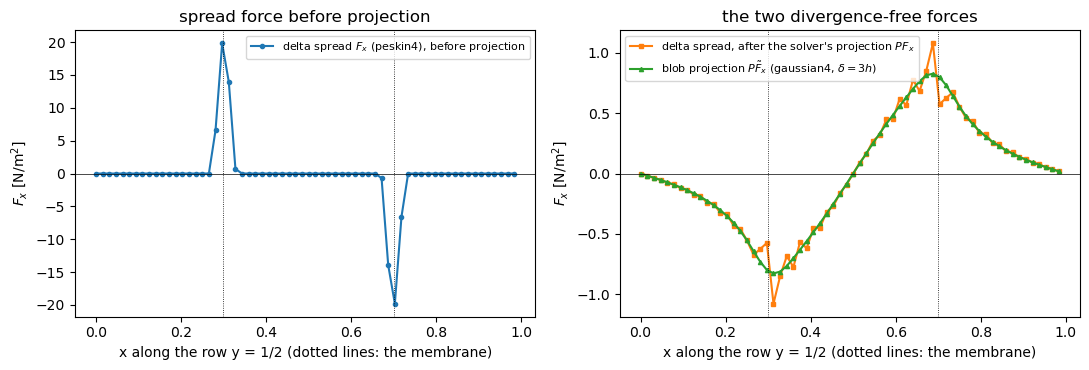

max |D0 . F| / max |D0 F|:  delta spread 1.131,  delta spread then projected 7.3e-16,  blob projection 1.4e-15
peak |F_x| on the row: delta spread 19.815, projected 1.077, blob 0.826 N/m^2
sum f ds over the ring = (-5.98e-17, -2.23e-16) N: a closed elastic ring exerts no net force, so all three grid fields have the same (zero) mean
sum F h^2: delta (-5.55e-17, 6.84e-18), blob (-1.01e-18, 5.20e-17)


In [12]:
f0 = compute_forces(ring, grid, 0.0, dt)
lay = layout_collocated(grid)
delta_c = DeltaCoupling(get_kernel("peskin4"))
Fdx, Fdy = delta_c.spread_vector(f0, X0, ring.ds, lay, lay)
sym = periodic_symbols(N, N, h)
Pdx, Pdy = [np.real(np.fft.ifft2(c)) for c in PeriodicFFTSolver.project(np.fft.fft2(Fdx), np.fft.fft2(Fdy), sym)]
blob_c = BlobProjection(grid, get_blob("gaussian4"), 3.0 * h)
Fbx, Fby = blob_c.projected_force(f0, X0, ring.ds)

j = N // 2
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(grid.x, Fdx[:, j], "o-", ms=3, color="C0", label="delta spread $F_x$ (peskin4), before projection")
axes[1].plot(grid.x, Pdx[:, j], "s-", ms=3, color="C1", label="delta spread, after the solver's projection $PF_x$")
axes[1].plot(grid.x, Fbx[:, j], "^-", ms=3, color="C2", label="blob projection $P\\tilde F_x$ (gaussian4, $\\delta = 3h$)")
for ax in axes:
    for xc in (0.5 - a, 0.5 + a):
        ax.axvline(xc, color="k", lw=0.6, ls=":")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("x along the row y = 1/2 (dotted lines: the membrane)"); ax.set_ylabel("$F_x$ [N/m$^2$]")
    ax.legend(fontsize=8)
axes[0].set_title("spread force before projection"); axes[1].set_title("the two divergence-free forces")
plt.tight_layout()
plt.show()

def rel_div(Fx, Fy):
    scale = max(np.abs(d0x(Fx, h)).max(), np.abs(d0y(Fy, h)).max())
    return np.abs(divergence(Fx, Fy, h)).max() / scale

print("max |D0 . F| / max |D0 F|:  delta spread %.3f,  delta spread then projected %.1e,  blob projection %.1e"
      % (rel_div(Fdx, Fdy), rel_div(Pdx, Pdy), rel_div(Fbx, Fby)))
print("peak |F_x| on the row: delta spread %.3f, projected %.3f, blob %.3f N/m^2"
      % (np.abs(Fdx[:, j]).max(), np.abs(Pdx[:, j]).max(), np.abs(Fbx[:, j]).max()))
print("sum f ds over the ring = (%.2e, %.2e) N: a closed elastic ring exerts no net force, so all three grid fields have the same (zero) mean"
      % tuple((f0 * ring.ds[:, None]).sum(axis=0)))
print("sum F h^2: delta (%.2e, %.2e), blob (%.2e, %.2e)" % (Fdx.sum() * h * h, Fdy.sum() * h * h, Fbx.sum() * h * h, Fby.sum() * h * h))

The spread force is a bump four cells wide, and most of it is a gradient: the inward tension of
a closed membrane is balanced by a pressure jump across it, which $P$ removes, so the peak drops
by more than an order of magnitude (printed above) and what is left is the part that actually
drives flow. The solver's projection leaves that remainder as sharp as the kernel, with the
discrete-gradient ringing of the centred $D_0$ around it. The blob projection is divergence-free
from the start, wider ($\delta = 3h$) and smoother, with the dipole tails visible away from the
membrane; its peak is of the same size as the projected delta force, as it should be, since both
are the solenoidal part of the same force. Now the dynamics.

initial area 0.157047 (pi a b = 0.157080)


delta             400 steps in 0.5 s (1.2 ms/step): relative area error at t = 0.40 is -3.61e-03, max over the run 3.61e-03; max|u| = 0.102, CFL = 0.009


blob              400 steps in 2.0 s (5.0 ms/step): relative area error at t = 0.40 is +1.06e-05, max over the run 1.27e-05; max|u| = 0.074, CFL = 0.006


delta, stream fn. 400 steps in 0.5 s (1.3 ms/step): relative area error at t = 0.40 is -7.54e-06, max over the run 1.73e-05; max|u| = 0.102, CFL = 0.009
size of the final area error, delta / blob: 339;  (delta, stream fn.) / blob: 0.71
largest area error over the run, (delta, stream fn.) / blob: 1.36


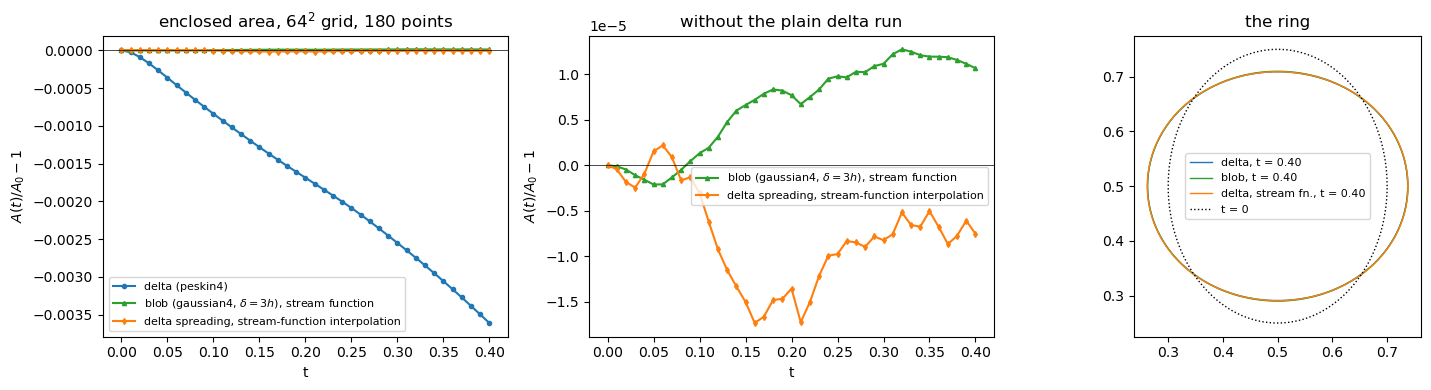

In [13]:
def params_for(coupling, interpolation="streamfunction"):
    return Parameters(fluid=FluidParams(rho=rho, mu=mu), time=TimeParams(Tfinal=0.4, dt=dt),
                      grid=GridParams(Nx=N, Ny=N, Lx=L, Ly=L),
                      solver=SolverParams(backend="periodic_fft", time_scheme="midpoint", coupling=coupling,
                                          kernel="peskin4", blob="gaussian4", blob_delta=3.0,
                                          blob_interpolation=interpolation),
                      bc=BCParams(), structure=StructureParams(name="ring", ds=ds),
                      output=OutputParams(print_dump=10**6, save_vtk=False, save_history=False, plot=False))

def area(X):
    '''Shoelace area of the closed polygon through the points (the ring never crosses the box edge).'''
    x, y = X[:, 0], X[:, 1]
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)

A0 = area(X0)
print("initial area %.6f (pi a b = %.6f)" % (A0, np.pi * a * b))
n_steps, every = 400, 10
cases = (("delta", "delta", "streamfunction"),              # delta coupling interpolates with its kernel; the key is unused
         ("blob", "blob", "streamfunction"),               # pyibm's default
         ("delta, stream fn.", "delta", "streamfunction"))  # the control: delta spreading, divergence-free interpolation
runs = {}
for label, coupling, interpolation in cases:
    sim = Simulation(params_for(coupling, interpolation), case_dir=os.getcwd(), hooks=Hooks(), structure=make_ring(), quiet=True)
    if label == "delta, stream fn.":
        # Teaching code, not an option of the driver: the force is still spread with peskin4, but the
        # markers move with the stream-function interpolant of section 5.2, which reads only the grid
        # velocity (the blob and its delta are not used by it).
        sim._interp = BlobProjection(grid, get_blob("gaussian4"), 3.0 * h).interpolate_streamfunction
    ts, errs = [0.0], [0.0]
    t0 = time.perf_counter()
    for _ in range(n_steps):
        sim.step()
        if sim.n % every == 0:
            ts.append(sim.t); errs.append(area(sim.structure.X) / A0 - 1.0)
    wall = time.perf_counter() - t0
    runs[label] = (np.array(ts), np.array(errs), sim)
    print("%-17s %d steps in %.1f s (%.1f ms/step): relative area error at t = %.2f is %+.2e, max over the run %.2e; max|u| = %.3f, CFL = %.3f"
          % (label, n_steps, wall, 1e3 * wall / n_steps, sim.t, errs[-1], np.abs(errs).max(),
             np.hypot(sim.solver.u, sim.solver.v).max(), sim.solver.cfl()))
final = {label: abs(run[1][-1]) for label, run in runs.items()}
largest = {label: np.abs(run[1]).max() for label, run in runs.items()}
print("size of the final area error, delta / blob: %.0f;  (delta, stream fn.) / blob: %.2f"
      % (final["delta"] / final["blob"], final["delta, stream fn."] / final["blob"]))
print("largest area error over the run, (delta, stream fn.) / blob: %.2f" % (largest["delta, stream fn."] / largest["blob"]))

styles = {"delta": ("C0", "o-", "delta (peskin4)"),
          "blob": ("C2", "^-", "blob (gaussian4, $\\delta = 3h$), stream function"),
          "delta, stream fn.": ("C1", "d-", "delta spreading, stream-function interpolation")}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for label, (ts, errs, sim) in runs.items():
    color, style, name = styles[label]
    axes[0].plot(ts, errs, style, ms=3, color=color, label=name)
    if label != "delta":
        axes[1].plot(ts, errs, style, ms=3, color=color, label=name)
    Xf = sim.structure.X
    axes[2].plot(np.append(Xf[:, 0], Xf[0, 0]), np.append(Xf[:, 1], Xf[0, 1]), "-", lw=1, color=color, label=label + ", t = %.2f" % sim.t)
for ax in axes[:2]:
    ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("t"); ax.set_ylabel("$A(t)/A_0 - 1$"); ax.legend(fontsize=8)
axes[0].set_title("enclosed area, $64^2$ grid, 180 points")
axes[1].set_title("without the plain delta run")
axes[2].plot(np.append(X0[:, 0], X0[0, 0]), np.append(X0[:, 1], X0[0, 1]), "k:", lw=1, label="t = 0")
axes[2].set_aspect("equal"); axes[2].set_title("the ring"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### What a full run shows (paper, section 4.1.1)

Our periodic FFT back end projects with the centred difference $D_0$, whose wide Laplacian
decouples the grid into four sub-grids. The paper's Fig. 4 shows that this is the worst of its
three projections for volume conservation in the immersed boundary method: on $128^2$ with 400
points, $\Delta t = 0.1h$, the relative volume error at $t = 1$ is about $-1.4\times10^{-2}$ with
that projection, about $-0.8\times10^{-3}$ with an exact spectral one and about $-2\times10^{-4}$
with the Peskin-Printz stencil derived from the delta function. Refining to $256^2$ and 800 points
(Fig. 5) only halves these errors: first-order volume conservation from a second-order method. So
the delta-coupling run above is the paper's worst immersed boundary case, and the ratios printed
above are measured against it, not against the Peskin-Printz projection. The markers of the delta
run move with the velocity interpolated by the delta function, which is not divergence-free in the
continuous sense; the markers of the blob run move with the stream-function interpolant of
section 5.2, which is.

The control run shows how much of the ratio that is. With its markers moved by the stream-function
interpolant, the delta coupling keeps this ring's area about as well as the blob: the two final
errors have opposite signs and the same size, and their largest errors over the run are of the
same size too (both ratios printed above). On this grid, then, the factor of a few hundred between
the delta and blob runs comes from the interpolation, not from spreading the force against
projecting it.

The blob projection method on the same problem keeps the volume error within about
$2\times10^{-5}$ on $128^2$ in all four of its runs (Fig. 8: gaussian4 or $\phi_8$, $\delta = 4h$
or $2h$; gaussian4 at $\delta = 4h$ stays within about $0.6\times10^{-5}$), smaller still on
$256^2$ (Fig. 7), and the paper calls it at least ten times better than the immersed boundary
result with comparable parameters; with fourth-order differencing and time stepping (Fig. 9)
refinement reduces the blob error by about a factor 6 against about 2 for the immersed boundary
method.

We also ran the ring of this section at the paper's grid, time step and blob ($128^2$, 400 points,
$\Delta t = 0.1h$, gaussian4 with $\delta = 4h$, $\nu = 0.005$, to $t = 1$; under a minute for the
blob run on a laptop, so not in this notebook). The relative area error at $t = 1$ was
$+1.0\times10^{-6}$ with the stream-function interpolant, at most $1.1\times10^{-6}$ over the run,
well inside the band of the paper's Fig. 8; $-5.3\times10^{-3}$ with delta coupling; and
$-7.9\times10^{-6}$, at most $1.3\times10^{-5}$ over the run, with delta spreading and the
stream-function interpolant (the control above, a few seconds on a laptop). With the same
divergence-free interpolation on both, the blob is about 8 times better than the delta function at
$t = 1$ and 12 times better in the largest error over the run. That is the part of the gain that
belongs to the blob on this ring; on the coarse $64^2$ grid above it does not show.

## 7. Resolution guidance and open items

**Resolution** (measured on this implementation; `docs/numerics.md` keeps the same guidance):

- The stream-function solve uses the tight five-point Laplacian by default. The wide
  $D_{0x}^2 + D_{0y}^2$ symbol decouples the four sub-grids and gave a checkerboard error of
  155 % in the far field for the compact blob at $\delta = 3h$ (the table in section 4); it remains
  available as `laplacian="wide"`. Both forms give an exactly $D_0$-divergence-free force with the
  exact total.
- Default patch half-width $\lceil R/h + 1/2\rceil$ nodes about the nearest node, with
  $R = \delta$ for the compact blob and $R = 3\delta$ for gaussian4. We take the gaussian4 patch
  out to $3\delta$ to keep the far field accurate: a disc of radius $2\delta$ keeps
  $F(2\delta) = 1.055$ of the Gaussian blob's mass, 5.5 % too much, because the gaussian4 tail
  beyond $\sqrt2\,\delta$ is negative, a square of half-width $2\delta$ keeps 1.032 (both
  printed in section 2), and with a square patch of that half-width the gaussian4 far field is
  off by several percent (section 4).
  `patch = 0` in the input file means automatic.
- gaussian4 wants $\delta \ge 3$-$4h$ and compact wants $\delta \ge 4h$ for about 1 % far-field
  error; at $3h$ the compact blob still works, with a far-field error of about 6 % (section 4).
  The paper's rules:
  $\delta > h$ so the velocity is regularised over several nodes, and $\delta > \Delta\ell$,
  with the boundary error minimal near $\delta \approx \Delta\ell$ and growing linearly in
  $\delta$ above it (section 4.2). Points still want $\Delta\ell$ somewhat below $h$.
- Interpolation: `blob_interpolation = "streamfunction"` (the default) is exactly divergence-free
  and keeps the area (section 6); `"bicubic"` interpolates $u$ and $v$ directly, so the
  interpolated field is divergence-free only to $O(h^2)$ and the area inside a closed membrane can
  drift slowly (section 5.2). With the compact blob at low viscosity, on a membrane without a
  bending term, the stream-function velocity can make the chain rough at the marker scale and
  the bicubic one can blow up; the `pyibm.coupling.blob` module docstring gives the cases we
  measured, in which only `BlobProjection(..., interpolation="adjoint")` (below) ran cleanly
  every time.
- Input file: `coupling = "blob"`, `blob = "gaussian4"` or `"compact"`, `blob_delta` in units
  of $h$, `patch` in nodes, `blob_interpolation`; `backend` must be `periodic_fft`.

**Open items** (what the implementation does not do, and why):

- *Quadrature weights.* Eq. 13 uses the trapezoid weight $\Delta\ell$ of the initial spacing;
  pyibm uses the fixed `ds` per point. Points do not stay equally spaced (section 4.1), and the
  paper's section 5 attributes its $O(\delta)$ boundary error, which caps the observed
  convergence at 2.5-3 when $\delta \propto h$, to computing a line integral on a 2D grid,
  suggesting Beale-Lai blob conditions and corrected trapezoid weights as the fix. Neither is
  implemented.
- *Energy.* Neither the stream-function nor the bicubic interpolation is the adjoint of the blob
  projection, so there is no discrete power identity of the Peskin kind between the work the
  structure does and the energy the fluid receives. Kinetic plus elastic energy is then not
  conserved, not even up to the time-stepping error. Released from rest without viscosity on
  $32^2$, a membrane with gaussian4 and the stream-function interpolation loses 22 % of its
  energy by $t = 0.5$ and holds 1.5 times its initial energy at $t = 2$ (the
  `pyibm.coupling.blob` module docstring and
  `tests/test_invariants.py::test_power_identity_delta_exact_blob_first_order` have these and
  the other numbers).
  Do not read the energy history of such a run as physical. `interpolation="adjoint"`,
  $U = \nabla^\perp_X \sum_{ij} h^2\psi_{ij}\,\phi_\delta(x_{ij} - X)$ plus the box mean, is the exact
  adjoint of `projected_force`: the fluid receives exactly the power the structure gives, and the
  velocity is divergence-free too, at the cost of a patch evaluation per call and a velocity that
  is a blob average. The driver's `fx_body` diagnostic, $-\sum F\,h^2$, is exact in total with
  every interpolation because the box mean is added explicitly.
- *The force type.* With `"bicubic"` the blob's gain over delta coupling holds for a mostly
  normal membrane force. For a purely tangential force both couplings then leak at about first
  order with similar sizes (`tests/test_invariants.py::test_static_leak_tangential_force`); the
  divergence-free default removes most of that leak too.
- *Pressure.* The fluid receives only $P\tilde F$, so the solver's own pressure holds no trace of
  the membrane. After every step the driver adds $p_F$ with $L_h p_F = \nabla\cdot\tilde F$
  (`BlobProjection.force_pressure`, from the force and positions the step used), so `solver.p` and
  the pressure output show the membrane's pressure jump, smeared over the width of the blob.
- *Periodic only.* Eq. 14 is a free-space kernel and the Poisson solve is an FFT on the doubly
  periodic box; `BlobProjection` raises on any other grid and the input-file validation ties
  `coupling = "blob"` to `backend = "periodic_fft"`. Walls would need a wall-aware Poisson solve
  for $\psi$ on the MAC grid, which is future work.
- *Net force.* A closed membrane exerts no net force, which is why the paper never needs the box
  mean. A tethered body does; `projected_force` adds the mean, and on the periodic box that mean
  accelerates the whole fluid unless `remove_mean_force = 1` holds the box-mean velocity fixed,
  exactly as with delta coupling.

## References

- R. Cortez and M. Minion, The blob projection method for immersed boundary problems, *J. Comput. Phys.* 161 (2000) 428-453.
- L. E. Fovargue, Addressing the computational cost of the immersed boundary method through multi-implicit and multi-rate strategies with time parallelism, PhD thesis, University of North Carolina at Chapel Hill (2012).
- C. S. Peskin and D. M. McQueen, Fluid dynamics of the heart and its valves, chapter 14 of H. G. Othmer, F. R. Adler, M. A. Lewis and J. C. Dallon (eds.), *Case Studies in Mathematical Modeling: Ecology, Physiology, and Cell Biology* (Prentice Hall, 1996), pp. 313-342.
- C. S. Peskin and B. F. Printz, Improved volume conservation in the computation of flows with immersed elastic boundaries, *J. Comput. Phys.* 105 (1993) 33-46.
- C. R. Anderson, A method of local corrections for computing the velocity field due to a distribution of vortex blobs, *J. Comput. Phys.* 62 (1986) 111-123.
- J. T. Beale and M.-C. Lai, A method for computing nearly singular integrals, *SIAM J. Numer. Anal.* 38 (2001) 1902-1925.

In [14]:
print("notebook wall time: %.1f s" % (time.perf_counter() - T_START))

notebook wall time: 6.2 s
